# Problem

## Locate suppressed interfacial magnetization from measured neutron spin contrast

Recover nuclear and magnetic scattering-length-density (SLD) depth profiles of a Mg-Al-Fe spinel film on MgAl2O4. We use all168 intensities from two actual polarized-beam reflectometer channels. The selected instrument-author case compares a uniform magnetic film with a film whose interfacial region has suppressed magnetization. This is a physical magnetic-depth inverse problem, not a fit of instrument calibration alone.

No independent magnetic depth truth is available. Our hidden method reference is a separately executed original Refl1D fit on the identical observations. The related Wisser2019 study used additional characterization and MCMC; this educational finite-layer case is explicitly distinguished from that paper's complete posterior. Both structures and all shared beam nuisance parameters are fitted afresh below.

In [1]:
from pathlib import Path
import os,sys,time,json,importlib.util
import numpy as np
import matplotlib.pyplot as plt
ROOT=Path.cwd()
if not (ROOT/'src').is_dir(): ROOT=ROOT.parent
sys.path.insert(0,str(ROOT))
from src.preprocessing import load_data
from src.solvers import reconstruct,fit_model
from src.visualization import observation_figure,profile_figure,sensitivity,sensitivity_figure
data=load_data(ROOT/'data/raw_data.npz')
with np.load(ROOT/'notebooks/reference_outputs/upstream.npz',allow_pickle=False) as z: original={k:z[k] for k in z.files}
spec=importlib.util.spec_from_file_location('task_judge',ROOT/'evaluation/judge.py');judge=importlib.util.module_from_spec(spec);spec.loader.exec_module(judge)
review=Path(os.environ.get('IMAGING_REVIEW_DIR',str(ROOT.parent.parent/'archive/review')));review.mkdir(parents=True,exist_ok=True)
def show(fig,name):
    fig.savefig(review/('pnr_'+name+'.png'),dpi=130);plt.show()
print('Measured spin channels and points:',data['reflectivity'].shape)
print('Every declared observation is used; no cached reconstruction path.')

Measured spin channels and points: (2, 84)
Every declared observation is used; no cached reconstruction path.


# Data

The source file records January2018 NCNR polarized-beam measurements and the instrument's background-subtraction, polarization-correction and footprint-correction chain. The two channels contain84 points each, retaining original uncertainties and angular/wavelength resolution. Wavelength is4.75 Angstrom. The film is saturated and collinear with the spin quantization axis; spin-flip channels were not measured in this selected dataset.

Substrate composition gives the independently known nuclear SLD5.377×10^-6 Angstrom^-2. Film properties remain unknown. The original tutorial called its added sample broadening a trial-and-error setting; we fit that quantity jointly in **both** models rather than providing it as independent calibration. Instrument-only resolution arrays remain public. Corrected intensities may have covariance not represented by the supplied per-point uncertainties, so reduced chi-square is a stated diagonal-noise diagnostic.

In [2]:
print('Nominal Q interval [Angstrom^-1]:',data['q'].min(),data['q'].max())
print('Instrument-only Q sigma interval:',data['q_resolution'].min(),data['q_resolution'].max())
print('All uncertainty values positive:',bool(np.all(data['uncertainty']>0)))
print('Fixed profile grid:',data['depth'][0],data['depth'][-1],len(data['depth']))

Nominal Q interval [Angstrom^-1]: 0.005997943623900001 0.19599798871
Instrument-only Q sigma interval: 0.00031534363808 0.0013471409962
All uncertainty values positive: True
Fixed profile grid: -40.0 220.0 521


# Physics

Neutron spin s=+1/-1 sees effective SLD rho+s rhoM, where rho is nuclear SLD and rhoM is proportional to magnetization along the quantization axis. In a collinear film the two spin channels decouple. With Q=4pi sin(theta+delta)/lambda, the layer wave number is

$$
k_{j,s}=\sqrt{(Q/2)^2-4\pi(\rho_j+s\rho^M_j)+4\pi i\eta}.
$$

Q is inverse Angstrom, lambda and layer thickness are Angstrom, theta/delta are angles converted from degrees, and eta=1e-16 inverse Angstrom squared preserves the original numerical branch guard. The measured reflection is the intensity of a coherent sum of multiple interface reflections. For Gaussian interface roughness sigma,

$$
f_j=\frac{k_j-k_{j+1}}{k_j+k_{j+1}}\exp(-2k_jk_{j+1}\sigma_j^2),\qquad
r_j=\frac{f_j+r_{j+1}\exp(2ik_{j+1}t_{j+1})}{1+f_jr_{j+1}\exp(2ik_{j+1}t_{j+1})}.
$$

The recursion begins with zero reflection in the semi-infinite substrate. t denotes each finite layer's thickness. Nuclear SLD is uniform through the film, while magnetic SLD is zero in an unbroadened interfacial layer of thickness d and constant m in the remaining thickness h-d. Gaussian roughness smooths these steps. Thus the smooth magnetic profile need not be exactly zero inside that nominal layer. Its integrated magnetic SLD is m(h-d).

Before comparing with measurements, intensity |r|² is integrated against the Gaussian Q resolution and scaled by the shared incident intensity. The implementation evaluates exact Gaussian integrals of the piecewise-linear84-point theory, using the original whole-interval cutoff and endpoint renormalization. Added sample angular broadening is combined with measured angular divergence and wavelength width before this convolution.

# Method

The local bounded Nelder-Mead implementation minimizes half the weighted sum of squared residuals:

$$
F(p)=\frac12\sum_{s,n}\left[\frac{R_{sn}(p)-y_{sn}}{\sigma_{sn}}\right]^2.
$$

p contains common intensity, added broadening, angular offset, buried/surface roughness, suppressed-layer thickness, magnetic/nuclear film SLD and total thickness. y and sigma are measured intensity and its reported uncertainty. Physical bounds and initial values are recorded in the plans. Every reflection, propagation phase, resolution integral, objective and inverse update is explicit local code.

The simplex uses reflection1, expansion2, contraction/shrink0.5 and initial coordinate radius15% of each bound range. Both convergence conditions are required: range-normalized vertex spread<=1e-7 and absolute objective spread<=1e-9. Original Bumps' status string is reversed despite normal numerical convergence; we checked the actual final simplex and report the criteria correctly. No original code is imported by this notebook, and no reference parameter initializes either fresh fit.

In [3]:
start=time.perf_counter();fresh,dead=reconstruct(data);dead_seconds=time.perf_counter()-start
start=time.perf_counter();uniform=fit_model(data,dead=False);uniform_seconds=time.perf_counter()-start
(ROOT/'output').mkdir(exist_ok=True);np.savez(ROOT/'output/reconstruction.npz',**fresh)
np.savez(ROOT/'notebooks/reference_outputs/cleaned.npz',**fresh,uniform_parameters=uniform['parameters'][None],uniform_profiles=uniform['profiles'][None],uniform_prediction=uniform['prediction'][None])
report,code=judge.evaluate(ROOT/'output/reconstruction.npz');assert code==0,report
print('Fresh complete fits [s]:',{'suppressed_interface':dead_seconds,'uniform':uniform_seconds})
print('Convergence:',{k:dead[k] for k in ['iterations','calls','scaled_size','objective_spread']})
print(json.dumps(report,indent=2))

Fresh complete fits [s]: {'suppressed_interface': 0.9977707999642007, 'uniform': 1.3714271999779157}
Convergence: {'iterations': 1091, 'calls': 1597, 'scaled_size': 9.201056035597806e-08, 'objective_spread': 5.4711790653527714e-12}
{
  "status": "pass",
  "passed": true,
  "metrics": {
    "parameter_range_error": 2.2480500779427834e-08,
    "nuclear_profile_nrmse": 5.832294239177285e-09,
    "magnetic_profile_nrmse": 2.38335776686682e-08,
    "profile_parameter_consistency": 0.0,
    "reduced_chi_square": 1.4722735348804543
  },
  "thresholds": {
    "parameter_range_error": {
      "comparison": "<=",
      "boundary": 0.0005
    },
    "nuclear_profile_nrmse": {
      "comparison": "<=",
      "boundary": 0.002
    },
    "magnetic_profile_nrmse": {
      "comparison": "<=",
      "boundary": 0.002
    },
    "profile_parameter_consistency": {
      "comparison": "<=",
      "boundary": 0.0001
    },
    "reduced_chi_square": {
      "comparison": "<=",
      "boundary": 1.545887211

# Results

## Actual reflectivity, spin asymmetry and residuals

Points/error bars are measured data; solid and dashed curves are the fresh fitted models. Crosses identify the independently executed original suppressed-layer fit. Spin asymmetry (R++-R--)/(R+++R--) highlights magnetic phase differences that can be difficult to see on a logarithmic reflectivity plot. The residual panels retain both complete channels, including high-Q observations. No missing comparison has been replaced by zero or an archive posing as a fresh fit.

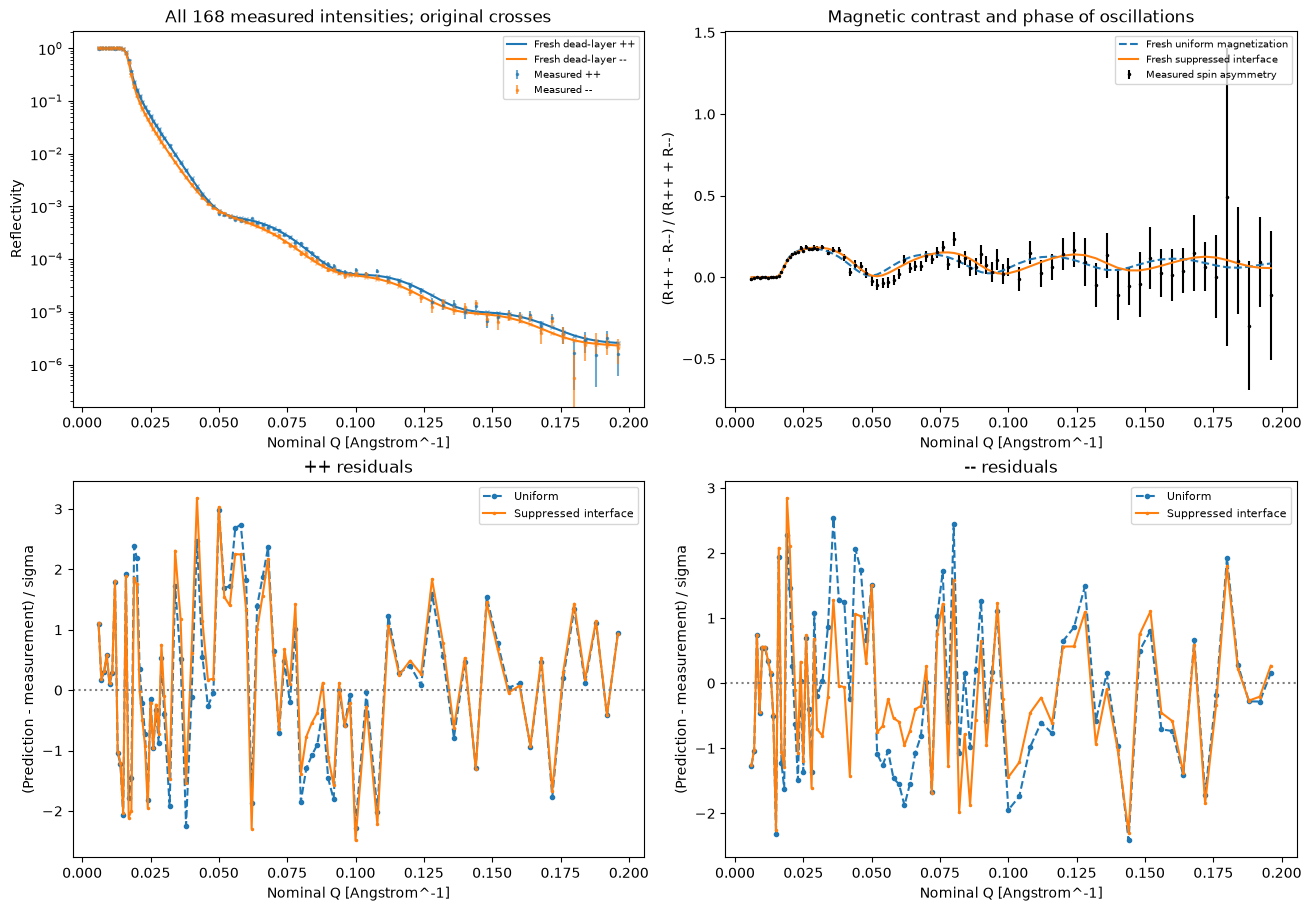

In [4]:
show(observation_figure(data,dead,uniform,original),'observations')

## Depth interpretation and independent reproduction

The smooth profiles below share a fixed physical interface origin. Nuclear contrast constrains structural thickness/composition, while polarized contrast identifies the magnetically suppressed interface. Original-method crosses are a parity reference, not independent truth. Both fits include unknown sample broadening, so improved dead-layer residuals cannot be attributed to giving only one model a tuned instrumental calibration.

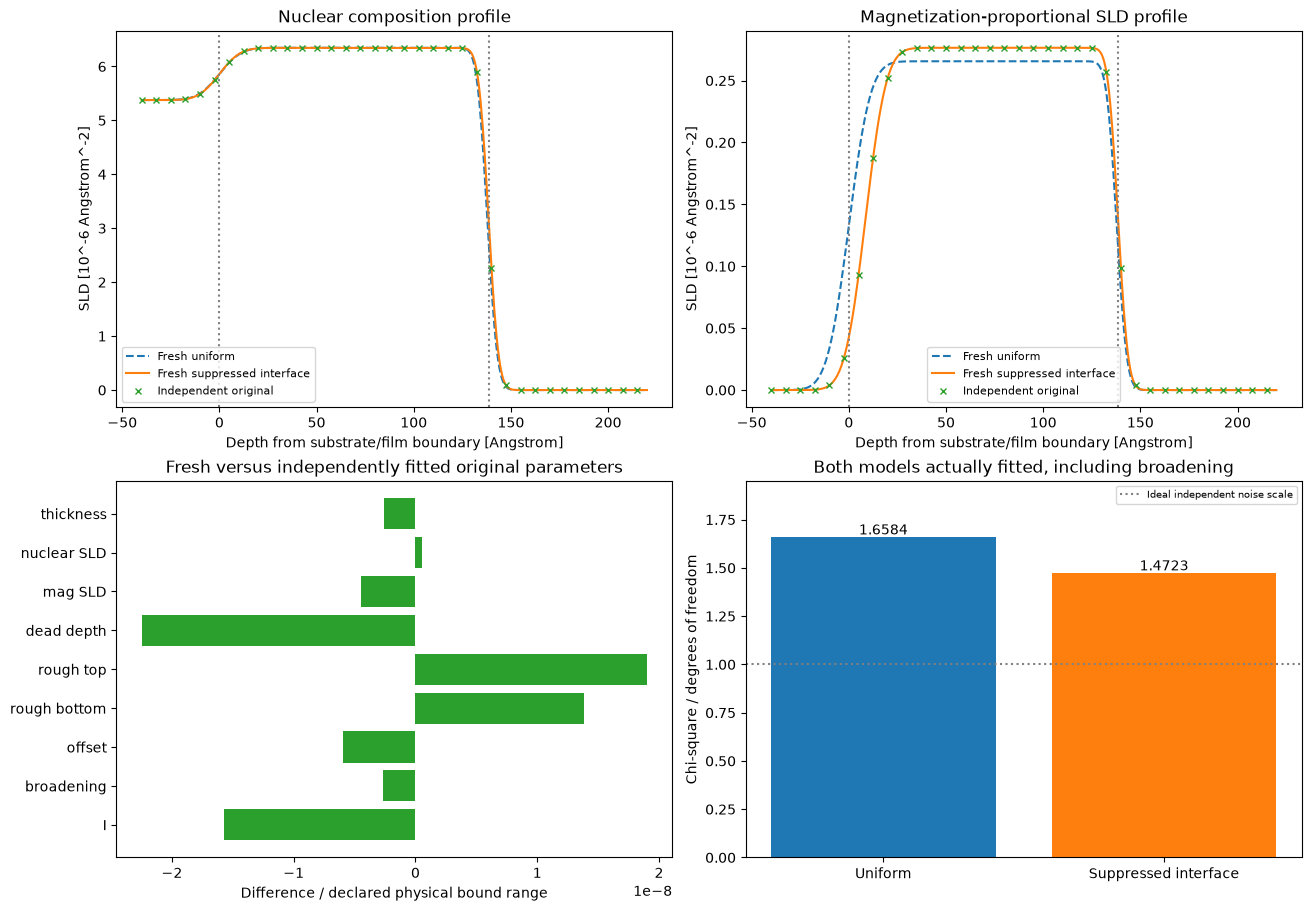

Method | reduced chi-square | provenance
Original uniform | 1.658374906392904 | independent bound-data execution
Fresh uniform | 1.6583749063928799 | active local fit
Original suppressed interface | 1.4722735348803904 | independent bound-data execution
Fresh suppressed interface | 1.4722735348804543 | active local fit
Historical paper | not compared numerically | different modeling/posterior experiment
Recovered suppressed thickness [Angstrom]: 8.572472189403687


In [5]:
show(profile_figure(data,dead,uniform,original),'profiles')
print('Method | reduced chi-square | provenance')
native_uniform=np.sum(((original['uniform_prediction'][0]-data['reflectivity'])/data['uncertainty'])**2)/(168-8)
native_dead=np.sum(((original['dead_prediction'][0]-data['reflectivity'])/data['uncertainty'])**2)/(168-9)
print('Original uniform |',native_uniform,'| independent bound-data execution')
print('Fresh uniform |',uniform['reduced_chi_square'],'| active local fit')
print('Original suppressed interface |',native_dead,'| independent bound-data execution')
print('Fresh suppressed interface |',dead['reduced_chi_square'],'| active local fit')
print('Historical paper | not compared numerically | different modeling/posterior experiment')
print('Recovered suppressed thickness [Angstrom]:',dead['parameters'][5])

## Conditional sensitivity and optimization evidence

The scans below recompute the full168-point forward model at81 values of suppressed thickness and81 values of added broadening while keeping other parameters fixed. They are **conditional slices**, not reoptimized profile likelihoods or confidence intervals. A centred finite-difference Jacobian supplies a local linearized correlation matrix under the diagonal uncertainty assumption. It shows why thickness, roughness and magnetic amplitude cannot be interpreted independently. The final panel displays the actually computed simplex history.

Local Jacobian rank: 9
Conditional linearized parameter standard deviations: [1.86665625e-03 9.32454017e-04 3.28350313e-04 7.78722074e-01
 1.35155895e-01 1.47378939e+00 4.87101398e-03 7.41205592e-03
 4.14326540e-01]


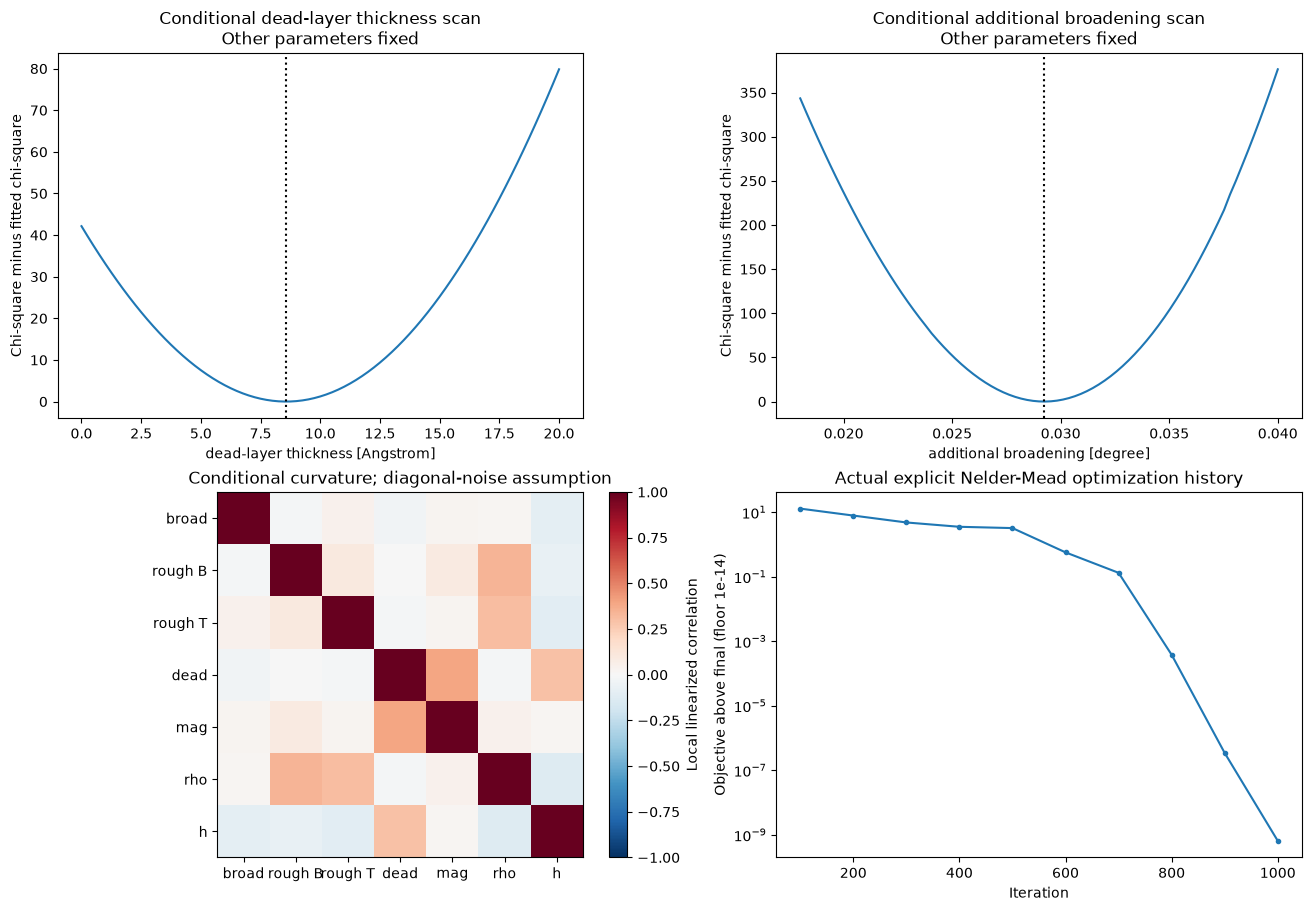

In [6]:
diagnostic=sensitivity(data,dead)
print('Local Jacobian rank:',np.linalg.matrix_rank(diagnostic['jacobian']))
print('Conditional linearized parameter standard deviations:',diagnostic['standard_deviation'])
show(sensitivity_figure(data,dead,diagnostic),'sensitivity')

# Conclusion

The fresh suppressed-interface fit improves both-channel agreement relative to uniform magnetization and reproduces the independent original numerical result. It resolves an effective interfacial magnetic suppression within this selected finite-layer family. No external magnetic ground truth was supplied, and phase loss, finite Q range, roughness overlap and missing covariance limit uniqueness.

The result is conditional on collinear magnetization, constant film nuclear composition, shared buried roughness and the stated beam model. Local curvature and fixed-parameter scans do not replace a full Bayesian posterior or independent microscopy. We preserve the original author's uniform/dead-layer spin-asymmetry comparison while making sample broadening an honest unknown. All fresh fits and displayed sensitivity calculations ran locally in this notebook.

Physical study: Wisser et al2019, DOI10.1063/1.5111326. Collinear polarized-wave theory: Maranville et al2016, arXiv1510.07912v2. Native case, exact code/data revisions, license notices and validation gates are documented in `test/validation.md`.